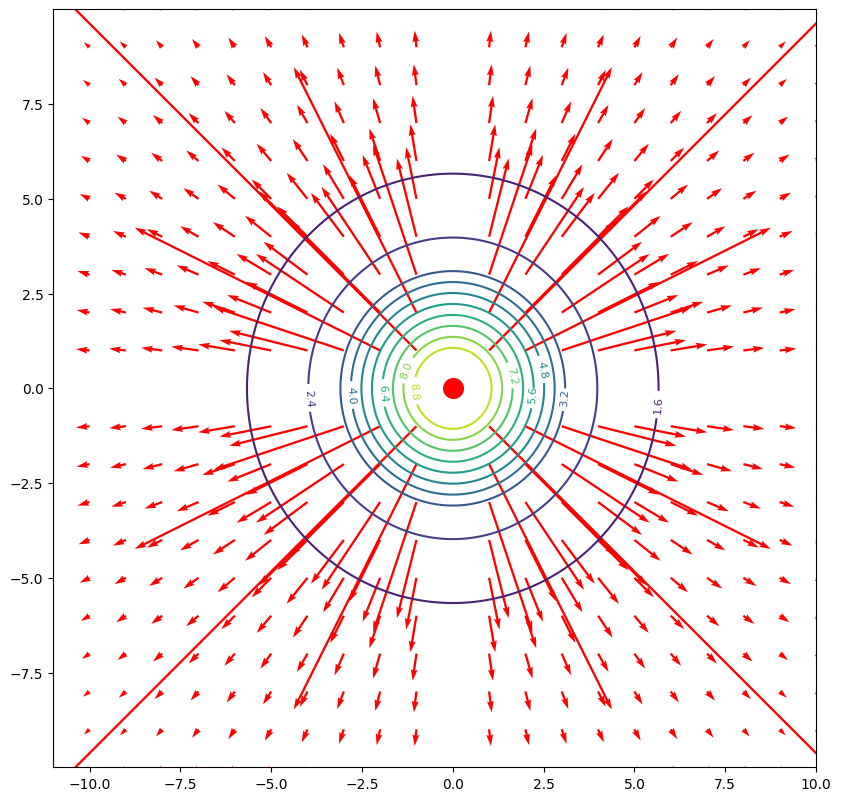

In [58]:
import matplotlib.pyplot as plt
import numpy as np

fronteira_x = 10
fronteira_y = 10

pontos_r = np.linspace(fronteira_x/10, fronteira_x, 5)
pontos_theta = np.linspace(0, 2*np.pi, 250)

pontos_quiver_x = np.array([-10, -9, -8, -7 , -6, -5, -4, -3, -2, -1, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
pontos_quiver_y = pontos_quiver_x
grade_quiver_x, grade_quiver_y = np.meshgrid(pontos_quiver_x, pontos_quiver_y)
angulos_quiver = np.arctan2(grade_quiver_y, grade_quiver_x)
vetores_unitarios_quiver_x = np.cos(angulos_quiver)
vetores_unitarios_quiver_y = np.sin(angulos_quiver)
distancias_quiver = np.sqrt(grade_quiver_x**2 + grade_quiver_y**2)


grade_r, grade_theta = np.meshgrid(pontos_r, pontos_theta)
grade_x = grade_r * np.cos(grade_theta)
grade_y = grade_r * np.sin(grade_theta)

# distancia do centro
distancias = np.sqrt(grade_x**2 + grade_y**2)

# vetores unitarios
angulos_vetores_unitarios = np.arctan2(grade_y, grade_x)
vetores_unitarios_x = np.cos(angulos_vetores_unitarios)
vetores_unitarios_y = np.sin(angulos_vetores_unitarios)

# vetor campo eletrico
constante = 1/(4*np.pi*8.85e-12)
carga = 1e-9
campo_eletrico_x = constante * carga / (distancias_quiver**2) * vetores_unitarios_quiver_x
campo_eletrico_y = constante * carga / (distancias_quiver**2) * vetores_unitarios_quiver_y

# linhas iso de potencial
potencial = 1/(4*np.pi*8.85e-12) * carga / distancias

fig, ax = plt.subplots()
fig.set_size_inches(25/2.54, 25/2.54)
ax.quiver(grade_quiver_x, grade_quiver_y, campo_eletrico_x, campo_eletrico_y, color='red', scale=5)
# ax.scatter(grade_x, grade_y, color='blue', s=1)
ax.scatter(0, 0,color='red', s=200)
contour = ax.contour(grade_x, grade_y, potencial, levels=10)
ax.clabel(contour, inline=True, fontsize=8)
fig.show()